# Preprocesamiento - Rendimiento Académico

# 1.Importación librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2.Importación fuente de datos

In [2]:
df_mat = pd.read_csv('../data/raw/student-mat.csv', sep=';')
df_por = pd.read_csv('../data/raw/student-por.csv', sep=';')

print(df_mat.shape, df_por.shape)

(395, 33) (649, 33)


## 2.1 Unión de las dos materias

In [3]:
df_mat['materia'] = 'matematicas'
df_por['materia'] = 'portugues'

df = pd.concat([df_mat, df_por], ignore_index=True)

print(df.shape)
df.head()

(1044, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,materia
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,matematicas
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,matematicas
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,matematicas
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,matematicas
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,matematicas


# 3.Análisis de Datos (EDA) + Preprocesado

## 3.1 Limpieza inicial

In [4]:
df.info()
print()
print("Nulos por columna:")
print(df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      1044 non-null   str  
 1   sex         1044 non-null   str  
 2   age         1044 non-null   int64
 3   address     1044 non-null   str  
 4   famsize     1044 non-null   str  
 5   Pstatus     1044 non-null   str  
 6   Medu        1044 non-null   int64
 7   Fedu        1044 non-null   int64
 8   Mjob        1044 non-null   str  
 9   Fjob        1044 non-null   str  
 10  reason      1044 non-null   str  
 11  guardian    1044 non-null   str  
 12  traveltime  1044 non-null   int64
 13  studytime   1044 non-null   int64
 14  failures    1044 non-null   int64
 15  schoolsup   1044 non-null   str  
 16  famsup      1044 non-null   str  
 17  paid        1044 non-null   str  
 18  activities  1044 non-null   str  
 19  nursery     1044 non-null   str  
 20  higher      1044 non-null   str  
 21  in

In [5]:
print("Filas duplicadas:", df.duplicated().sum())
df.describe().transpose()

Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.0,18.0,22.0
Medu,1044.0,2.603448,1.124907,0.0,2.0,3.0,4.0,4.0
Fedu,1044.0,2.387931,1.099938,0.0,1.0,2.0,3.0,4.0
traveltime,1044.0,1.522989,0.731727,1.0,1.0,1.0,2.0,4.0
studytime,1044.0,1.970307,0.834353,1.0,1.0,2.0,2.0,4.0
failures,1044.0,0.264368,0.656142,0.0,0.0,0.0,0.0,3.0
famrel,1044.0,3.935824,0.933401,1.0,4.0,4.0,5.0,5.0
freetime,1044.0,3.201149,1.031507,1.0,3.0,3.0,4.0,5.0
goout,1044.0,3.156130,1.152575,1.0,2.0,3.0,4.0,5.0
Dalc,1044.0,1.494253,0.911714,1.0,1.0,1.0,2.0,5.0


In [6]:
print("Estudiantes con G3 = 0:", (df['G3'] == 0).sum())
print("Estudiantes con absences >= 30:", (df['absences'] >= 30).sum())

df[df['G3'] == 0][['materia', 'absences', 'G1', 'G2', 'G3']].head(10)

Estudiantes con G3 = 0: 53
Estudiantes con absences >= 30: 8


,materia,absences,G1,G2,G3
128,matematicas,0,7,4,0
130,matematicas,0,12,0,0
131,matematicas,0,8,0,0
134,matematicas,0,9,0,0
135,matematicas,0,11,0,0
136,matematicas,0,10,0,0
137,matematicas,0,4,0,0
140,matematicas,0,7,9,0
144,matematicas,0,5,0,0
146,matematicas,0,6,7,0


In [7]:
ceros = df[df['G3'] == 0]

print("Por materia:")
print(ceros['materia'].value_counts())
print()
print("Con absences = 0:", (ceros['absences'] == 0).sum())
print("Con G2 = 0:", (ceros['G2'] == 0).sum())

Por materia:
materia
matematicas    38
portugues      15
Name: count, dtype: int64

Con absences = 0: 53
Con G2 = 0: 20


**Hallazgos de la limpieza inicial**

- No hay valores nulos ni filas duplicadas en los 1044 registros.
- Los rangos de las variables son coherentes (notas entre 0 y 20).
- Hay 53 estudiantes con G3 = 0 (38 de matemáticas y 15 de portugués). Todos tienen 0 faltas y 20 tienen también G2 = 0.
- Hay 8 estudiantes con 30 o más faltas (el máximo es 75).
- Decisión: por ahora no se eliminan estos casos, porque representan estudiantes en riesgo alto que el modelo debe aprender a detectar.

### Validación de categorías y rangos

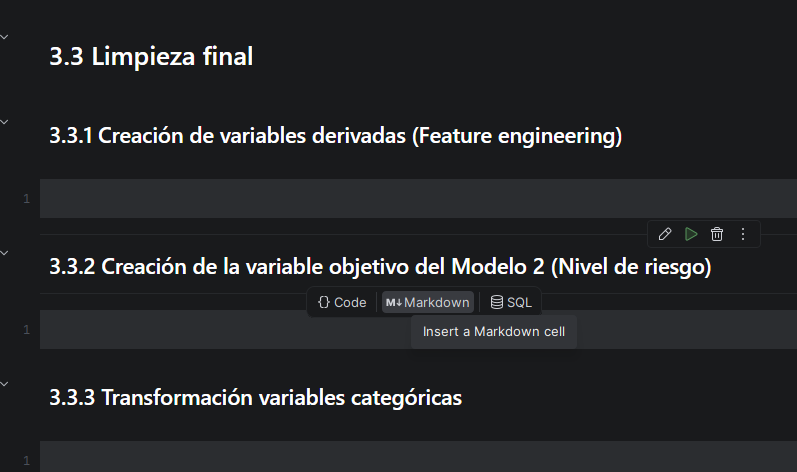

In [8]:
#Revisamos los valores únicos de cada columna de texto para detectar errores de escritura o categorías inesperadas
columnas_texto = df.select_dtypes(exclude='number').columns
for col in columnas_texto:
    print(col, list(df[col].unique()))

school ['GP', 'MS']
sex ['F', 'M']
address ['U', 'R']
famsize ['GT3', 'LE3']
Pstatus ['A', 'T']
Mjob ['at_home', 'health', 'other', 'services', 'teacher']
Fjob ['teacher', 'other', 'services', 'health', 'at_home']
reason ['course', 'other', 'home', 'reputation']
guardian ['mother', 'father', 'other']
schoolsup ['yes', 'no']
famsup ['no', 'yes']
paid ['no', 'yes']
activities ['no', 'yes']
nursery ['yes', 'no']
higher ['yes', 'no']
internet ['no', 'yes']
romantic ['no', 'yes']
materia ['matematicas', 'portugues']


Todas las columnas de texto contienen únicamente las categorías indicadas en el diccionario de datos, sin errores de escritura ni valores inesperados.

In [9]:
#Rangos válidos de cada variable numérica según el diccionario de datos (student.txt)
rangos_validos = {
    'age': (15, 22),
    'Medu': (0, 4),
    'Fedu': (0, 4),
    'traveltime': (1, 4),
    'studytime': (1, 4),
    'failures': (0, 4),
    'famrel': (1, 5),
    'freetime': (1, 5),
    'goout': (1, 5),
    'Dalc': (1, 5),
    'Walc': (1, 5),
    'health': (1, 5),
    'absences': (0, 93),
    'G1': (0, 20),
    'G2': (0, 20),
    'G3': (0, 20)
}

#Verificamos que todos los valores de cada columna estén dentro de su rango válido
for col, (minimo, maximo) in rangos_validos.items():
    fuera_de_rango = ((df[col] < minimo) | (df[col] > maximo)).sum()
    print(col, '- rango', minimo, 'a', maximo, '- valores fuera de rango:', fuera_de_rango)

age - rango 15 a 22 - valores fuera de rango: 0
Medu - rango 0 a 4 - valores fuera de rango: 0
Fedu - rango 0 a 4 - valores fuera de rango: 0
traveltime - rango 1 a 4 - valores fuera de rango: 0
studytime - rango 1 a 4 - valores fuera de rango: 0
failures - rango 0 a 4 - valores fuera de rango: 0
famrel - rango 1 a 5 - valores fuera de rango: 0
freetime - rango 1 a 5 - valores fuera de rango: 0
goout - rango 1 a 5 - valores fuera de rango: 0
Dalc - rango 1 a 5 - valores fuera de rango: 0
Walc - rango 1 a 5 - valores fuera de rango: 0
health - rango 1 a 5 - valores fuera de rango: 0
absences - rango 0 a 93 - valores fuera de rango: 0
G1 - rango 0 a 20 - valores fuera de rango: 0
G2 - rango 0 a 20 - valores fuera de rango: 0
G3 - rango 0 a 20 - valores fuera de rango: 0


Todas las variables numéricas se encuentran dentro de los rangos indicados en el diccionario de datos. No se detectaron valores inválidos, por lo que no es necesario corregir ni eliminar registros.

## 3.3 Limpieza final

### 3.3.1 Creación de variables derivadas (Feature engineering)

In [10]:
# Promedio de las notas parciales del primer y segundo periodo
# IMPORTANTE: esta variable usa G1 y G2, por tanto en el Modelo 1 'sin G1/G2' también se debe eliminar
df['promedio_notas'] = (df['G1'] + df['G2']) / 2

In [11]:
# Tasa de ausencias: proporción de ausencias respecto al máximo posible indicado en el diccionario de datos (93)
df['tasa_ausencias'] = df['absences'] / 93

In [12]:
df[['G1','G2','promedio_notas','absences','tasa_ausencias']].head()

,G1,G2,promedio_notas,absences,tasa_ausencias
0,5,6,5.5,6,0.064516
1,5,5,5.0,4,0.043011
2,7,8,7.5,10,0.107527
3,15,14,14.5,2,0.021505
4,6,10,8.0,4,0.043011


### 3.3.2 Creación de la variable objetivo del Modelo 2 (Nivel de riesgo)

In [13]:
def calcular_nivel_riesgo(g3):
    if g3 >= 14:
        return 1 #Sin riesgo
    elif g3 >= 12:
        return 2 #Riesgo bajo
    elif g3 >= 10:
        return 3 #Riesgo medio
    else:
        return 4 #Riesgo alto

In [14]:
df['nivel_riesgo'] = df['G3'].apply(lambda x: calcular_nivel_riesgo(x))

In [15]:
#Verificar si hay una proporción equilibrada entre los diferentes valores de la variable objetivo para un buen modelado posterior
df['nivel_riesgo'].value_counts().sort_index()

nivel_riesgo
1    294
2    216
3    304
4    230
Name: count, dtype: int64

<Axes: xlabel='nivel_riesgo', ylabel='count'>

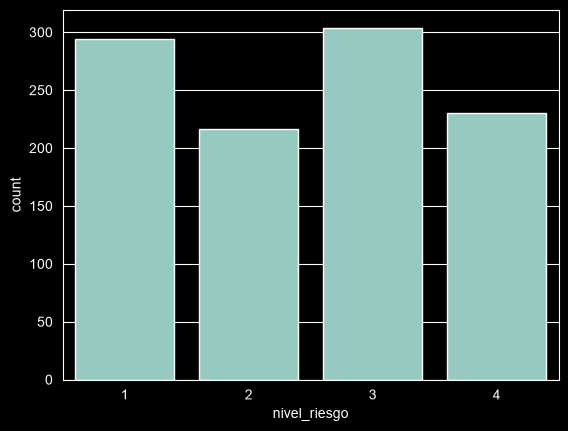

In [16]:
sns.countplot(x='nivel_riesgo',data=df)

**Criterio del nivel de riesgo**

El dataset no incluye una variable de nivel de riesgo, por lo que se construye a partir de la nota final G3 (escala 0 a 20). En el sistema educativo portugués la nota mínima para aprobar es 10.

| Nivel | Rango G3 | Significado |
|---|---|---|
| 1 | 14 - 20 | Sin riesgo |
| 2 | 12 - 13 | Riesgo bajo |
| 3 | 10 - 11 | Riesgo medio (aprueba por poco) |
| 4 | 0 - 9 | Riesgo alto (reprueba) |

A mayor valor, mayor riesgo. Con estos rangos las cuatro clases quedan equilibradas (294, 216, 304 y 230 estudiantes), lo cual favorece el entrenamiento del modelo de clasificación multiclase.

### 3.3.3 Transformación variables categóricas

In [17]:
#Columnas de tipo texto que hay que transformar a números
columnas_categoricas = df.select_dtypes(exclude='number').columns.tolist()
columnas_categoricas

['school',
 'sex',
 'address',
 'famsize',
 'Pstatus',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'materia']

In [18]:
#Transformar variables categóricas en columnas dummy (una columna por categoría con valor 0 o 1)
dummies = pd.get_dummies(df[columnas_categoricas],dtype=int) #se puede añadir drop_first=True evita redundancia y evita crear una columna por cada variable
df_post = pd.concat([df,dummies],axis=1)
df_post = df_post.drop(columnas_categoricas,axis=1) #Eliminamos las columnas originales

In [19]:
df_post.shape

(1044, 64)

In [20]:
df_post.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,materia_matematicas,materia_portugues
0,18,4,4,2,2,0,4,3,4,1,...,0,1,0,1,1,0,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,...,1,0,0,1,0,1,1,0,1,0
2,15,1,1,1,2,3,4,3,2,2,...,0,1,0,1,0,1,1,0,1,0
3,15,4,2,1,3,0,3,2,2,1,...,0,1,0,1,0,1,0,1,1,0
4,16,3,3,1,2,0,4,3,2,1,...,0,1,0,1,1,0,1,0,1,0


In [21]:
#Correlación de las variables con la nota final G3
df_post.corr(numeric_only = True)['G3'].sort_values()

nivel_riesgo          -0.868410
failures              -0.383145
higher_no             -0.236578
materia_matematicas   -0.187166
Dalc                  -0.129642
                         ...   
higher_yes             0.236578
G1                     0.809142
promedio_notas         0.894479
G2                     0.910743
G3                     1.000000
Name: G3, Length: 64, dtype: float64

**Observaciones de la correlación con G3**

- Las variables más relacionadas con la nota final son G2, G1 y promedio_notas (positivas) y failures (negativa).
- Sin las notas parciales, las variables con mayor relación son failures, higher_no y materia_matematicas, lo que anticipa que el Modelo 1 sin G1/G2 tendrá un desempeño menor.
- nivel_riesgo se deriva de G3, por lo que no debe usarse como variable de entrada en el Modelo 1.

# 4.Train Test Split

In [22]:
#Variables objetivo: G3 (Modelo 1 - Regresión) y nivel_riesgo (Modelo 2 - Clasificación multiclase)
variables_objetivo = ['G3','nivel_riesgo']
X = df_post.drop(variables_objetivo,axis=1)
y = df_post[variables_objetivo]

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=101) #80% Entrenamiento / 20% Test

In [25]:
X_train.shape

(835, 62)

In [26]:
X_test.shape

(209, 62)

# 5.Escalado

In [27]:
from sklearn.preprocessing import MinMaxScaler

In [28]:
#Transforma los datos para que estén en un rango específico, generalmente entre 0 y 1
scaler = MinMaxScaler()

In [29]:
scaler.fit(X_train) #El scaler se ajusta SOLO con los datos de entrenamiento

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](62,)","[22., 4., 4.,..., 1., 1., 1.]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](62,)","[15., 0., 0.,..., 0., 0., 0.]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](62,)","[7.,4.,4.,...,1.,1.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](62,)","['age','Medu','Fedu',...,'romantic_yes','materia_matematicas', 'materia_portugues']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](62,)","[-2.14, 0. , 0. ,..., 0. , 0. , 0. ]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,62
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,835


In [30]:
X_train_esc = scaler.transform(X_train)
X_test_esc = scaler.transform(X_test)

In [31]:
X_train_esc.max(), X_train_esc.min()

(np.float64(1.0), np.float64(0.0))

# 6.Guardar datos procesados

- `data/processed/train.csv` y `test.csv`: datos limpios con dummies, **sin escalar**, incluyen G3 y nivel_riesgo. Cada modelo elimina las columnas que no utiliza (por ejemplo G1, G2 y promedio_notas en el Modelo 1 sin notas parciales) y aplica su escalado.
- `models/scaler.pkl`: MinMaxScaler entrenado con todas las variables de entrada.
- `models/columnas.pkl`: columnas finales tras get_dummies (las necesita la API para preparar los datos nuevos).

In [32]:
import joblib

In [33]:
#Unimos de nuevo las variables de entrada con las variables objetivo
train = pd.concat([X_train,y_train],axis=1)
test = pd.concat([X_test,y_test],axis=1)
train.shape, test.shape

((835, 64), (209, 64))

In [34]:
train.to_csv('../data/processed/train.csv',index=False)
test.to_csv('../data/processed/test.csv',index=False)

In [35]:
joblib.dump(scaler,'../models/scaler.pkl')
joblib.dump(X.columns.tolist(),'../models/columnas.pkl')

['../models/columnas.pkl']

In [36]:
#Verificamos que los archivos se guardaron correctamente
pd.read_csv('../data/processed/train.csv').head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,materia_matematicas,materia_portugues,G3,nivel_riesgo
0,16,3,3,1,2,0,4,3,2,1,...,0,1,1,0,1,0,0,1,13,2
1,15,3,2,1,2,0,4,2,2,1,...,0,1,0,1,1,0,1,0,19,1
2,16,4,3,1,2,0,5,4,2,1,...,0,1,0,1,1,0,0,1,13,2
3,16,2,3,1,2,0,2,3,1,1,...,0,1,0,1,1,0,0,1,14,1
4,17,1,1,3,1,1,5,2,1,1,...,0,1,0,1,0,1,1,0,0,4
